
Baseline Decision Tree Accuracy: 0.9319118003392295

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96      3507
Failure Soon       0.77      0.79      0.78       620

    accuracy                           0.93      4127
   macro avg       0.86      0.87      0.87      4127
weighted avg       0.93      0.93      0.93      4127


Depth vs Splitting Criteria Analysis (Sample):
  criterion max_depth  train_acc  test_acc
0      gini         2   0.937227  0.941119
1      gini         3   0.942802  0.945239
2      gini         4   0.943953  0.943785
3      gini         5   0.948558  0.946693
4      gini         6   0.953284  0.947177
5      gini         8   0.963948  0.941604
6      gini        10   0.979217  0.936516
7      gini        15   0.997395  0.928277
8      gini      None   1.000000  0.931912
9   entropy         2   0.930805  0.934335

Experiment 6 Completed Successfully


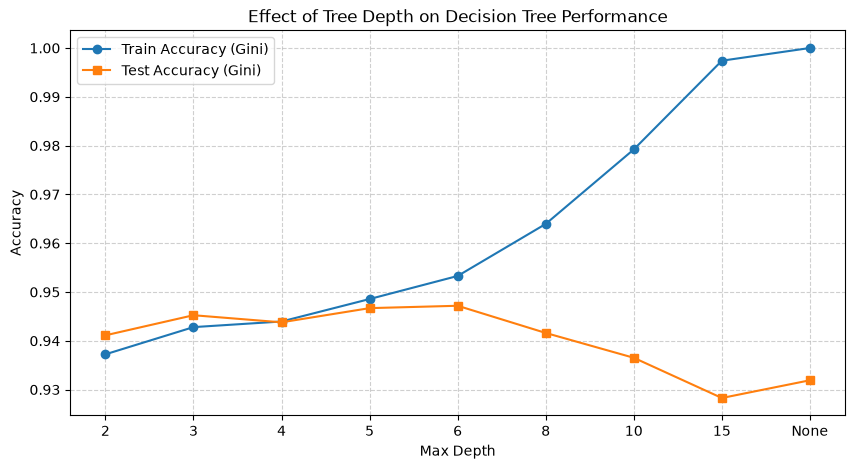

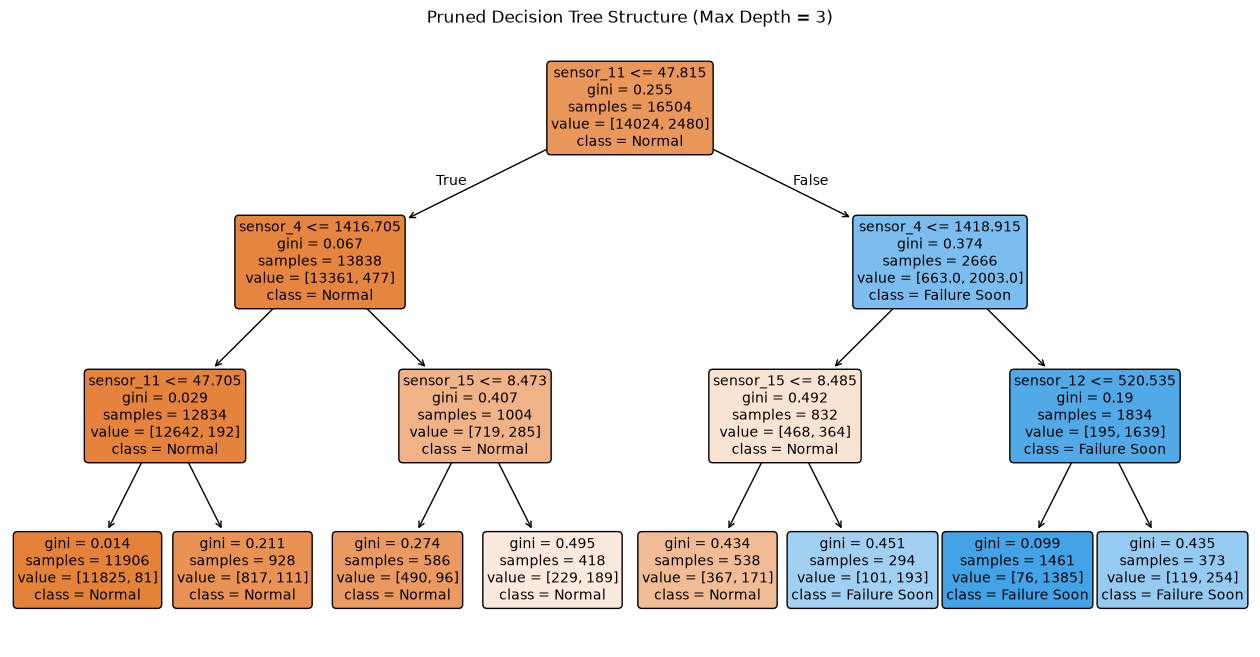

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Load CMAPSS turbofan dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

# Calculate Remaining Useful Life (RUL) and binary failure target (within 30 cycles)
df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

# Select key sensor features showing degradation patterns
features = ["cycle", "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
X = df[features]
y = df["failure_soon"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 1. Baseline Decision Tree
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)
y_pred_base = dt_baseline.predict(X_test)

print("\nBaseline Decision Tree Accuracy:", accuracy_score(y_test, y_pred_base))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_base, target_names=["Normal", "Failure Soon"]))

# 2. Study effect of Tree Depth and Splitting Criteria (Gini vs Entropy)
depths = [2, 3, 4, 5, 6, 8, 10, 15, None]
results = []

for criterion in ["gini", "entropy"]:
    for d in depths:
        clf = DecisionTreeClassifier(criterion=criterion, max_depth=d, random_state=42)
        clf.fit(X_train, y_train)
        train_acc = accuracy_score(y_train, clf.predict(X_train))
        test_acc = accuracy_score(y_test, clf.predict(X_test))
        results.append({"criterion": criterion, "max_depth": str(d), "train_acc": train_acc, "test_acc": test_acc})

results_df = pd.DataFrame(results)
print("\nDepth vs Splitting Criteria Analysis (Sample):")
print(results_df.head(10))

# Plot effect of tree depth on Train vs Test Accuracy
plt.figure(figsize=(10, 5))
gini_res = results_df[results_df["criterion"] == "gini"].copy()
depth_labels = [2, 3, 4, 5, 6, 8, 10, 15, 20]
plt.plot(range(len(depth_labels)), gini_res["train_acc"], marker="o", label="Train Accuracy (Gini)")
plt.plot(range(len(depth_labels)), gini_res["test_acc"], marker="s", label="Test Accuracy (Gini)")
plt.xticks(range(len(depth_labels)), [c if c != "None" else "None" for c in gini_res["max_depth"]])
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Decision Tree Performance")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 3. Visualizing pruned Decision Tree (max_depth=3)
pruned_tree = DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)
pruned_tree.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(pruned_tree, feature_names=features, class_names=["Normal", "Failure Soon"], filled=True, rounded=True, fontsize=10)
plt.title("Pruned Decision Tree Structure (Max Depth = 3)")
plt.show()

print("Experiment 6 Completed Successfully")